# TD MAUP - M2 IGAST - CORRECTION

## Comprendre le MAUP sur un cas pratique

Nous allons illustrer le MAUP avec la consommation d'espaces en France métropolitaine, à cinq maillages.

Les données viennent du Cerema. Il s'agit des surfaces d'espaces naturels, agricoles et forestiers (ENAF) consommées entre le 1er janvier 2011 et le 1er janvier 2025, par commune, en hectares.

L'indicateur du TD est la **part du territoire consommée en espaces naturels, agricoles et forestiers entre 2011 et 2025 (%)**. Dans la suite, on l'appelle plus simplement *taux de consommation d'espaces* (colonne `txartif`).

En clair : on compte les hectares de nature, de terres agricoles et de forêts qui ont été transformés en logements, routes, zones d'activité, etc. entre 2011 et 2025, et on les rapporte à la surface totale du territoire. Par exemple, une commune de 1 000 ha qui a perdu 15 ha d'espaces naturels, agricoles ou forestiers au profit de constructions a un taux de 1,5 %.

C'est un flux sur 14 ans, pas la part des sols artificialisés à une date. Une commune qui a beaucoup consommé n'est donc pas forcément « plus artificialisée » qu'une autre. Le [Cerema](https://doc-datafoncier.cerema.fr/doc/guide/conso-enaf/definition-de-la-consommation-despace) détaille la différence entre consommation d'espaces et artificialisation.

Chaque réponse s'appuie sur au moins un chiffre tiré de vos résultats, puis en donne une interprétation et une limite.

## Comment se déroule le TD

Le but est d'**interpréter des résultats**, pas d'apprendre Python. Chaque partie suit le même schéma :

1. **Exemple** : un code complet, écrit pour les communes. Il suffit de l'exécuter et de lire ce qu'il produit. Les commentaires (lignes qui commencent par `#`) expliquent chaque étape.
2. **À vous** : vous refaites la même chose pour les autres mailles. Il suffit de copier l'exemple et de changer le nom de la maille. Vous n'avez rien à programmer.
3. **Questions** : vous interprétez ce que vous voyez.

Quelques repères pour lire le code :

| Ce que vous voyez | Ce que cela veut dire |
|:--|:--|
| `epci_artif = charger('EPCI')` | Le résultat de droite est rangé dans une variable nommée `epci_artif` |
| `gdf['txartif']` | La colonne `txartif` du tableau `gdf` |
| `carte(epci_artif, "EPCI")` | On appelle une fonction déjà écrite, avec ses arguments entre parenthèses |
| `# texte` | Un commentaire, ignoré par Python |

Les cellules s'exécutent dans l'ordre, de haut en bas (`Maj + Entrée`). Une erreur `NameError` signifie en général qu'une cellule précédente n'a pas été exécutée.

## Avant la séance

Le notebook se lit sur GitHub, mais il ne s'y exécute pas. Il s'ouvre dans JupyterLab, dans un environnement Python local. Les consignes pour installer cet environnement avec conda sont dans le [README du dépôt](https://github.com/fbxyz/M2_IGAST/blob/master/README.md#installation-et-utilisation-de-jupyterlab). Les fichiers de données sont aussi dans le dossier `data` du dépôt, à télécharger si la connexion est lente.

---

# 1 - Chargement et contrôle des données

Les cinq maillages regroupent les mêmes 34 735 communes.

| Maille | Fichier | Identifiant | Surface de la maille (ha) |
|:--|:--|:--|:--|
| Communes | `MAUP_COM_ARTIF_3857.geojson` | `insee_com` | `surface_com` |
| EPCI | `MAUP_EPCI_ARTIF_3857.geojson` | `insee_epci` | `surface_epci` |
| Départements | `MAUP_DEP_ARTIF_3857.geojson` | `insee_dep` | `surface_dept` |
| Anciennes régions (avant 2016) | `MAUP_OLDREG_ARTIF_3857.geojson` | `insee_old_reg` | `surface_oldreg` |
| Nouvelles régions (depuis 2016) | `MAUP_REG_ARTIF_3857.geojson` | `insee_reg` | `surface_reg` |

Tous les fichiers contiennent aussi `surface_artif` (surface d'ENAF consommée entre 2011 et 2025, en hectares), `pop11` et `pop22` (population en 2011 et en 2022, Insee).

Le nom de la colonne de surface change d'une maille à l'autre. Le taux se calcule avec toute la précision disponible, `round()` ne sert qu'à l'affichage.

## 1.1 - Communes : *com_artif*

**Exemple à exécuter.** La cellule ci-dessous lit le fichier des communes, change sa projection, puis calcule le taux de consommation d'espaces.

- `gpd.read_file(...)` lit le fichier GeoJSON et crée un *GeoDataFrame*, c'est-à-dire un tableau où chaque ligne est une commune avec sa géométrie.
- `.to_crs(epsg=2154)` change la **projection**. Les fichiers sont en Web Mercator (EPSG:3857), la projection des cartes en ligne, qui étire les territoires vers le nord. On passe en Lambert-93 (EPSG:2154), la projection officielle pour la France métropolitaine, pour que la carte ait la bonne forme. Les surfaces en hectares sont déjà dans les fichiers : la reprojection change l'allure de la carte, pas le taux.
- Le taux est calculé colonne par colonne : surface consommée divisée par surface de la commune, multipliée par 100.

La fonction `charger()` regroupe ces étapes pour n'importe quelle maille. Vous n'avez pas à la modifier, seulement à l'appeler.

In [1]:
# geopandas lit les fichiers géographiques et les range dans des tableaux (GeoDataFrame)
# https://geopandas.org/
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mapclassify as mc
import numpy as np

sns.set_theme(style="whitegrid")

# Adresse des fichiers : {} sera remplacé par le nom de la maille (COM, EPCI, DEP...)
URL = "https://github.com/fbxyz/M2_IGAST/raw/master/data/MAUP_{}_ARTIF_3857.geojson"
# Texte de légende utilisé dans les cartes et les graphiques
LEG = "Part du territoire consommée 2011-2025 (%)"

# 1. Charger le fichier GeoJSON des communes
com_artif = gpd.read_file(URL.format("COM"))
print(com_artif.crs)  # projection d'origine : EPSG:3857 (Web Mercator)

# 2. Changer la projection vers Lambert-93 (EPSG:2154)
com_artif = com_artif.to_crs(epsg=2154)

# 3. Calculer le taux de consommation d'espaces 2011-2025, en pleine précision (pas de round ici)
com_artif['txartif'] = 100 * com_artif['surface_artif'] / com_artif['surface_com']

# 4. Afficher les premières lignes pour vérifier le résultat
print(com_artif.head())

# Pour chaque maille : nom -> (code du fichier, colonne de surface)
MAILLES = {'Communes': ('COM', 'surface_com'), 'EPCI': ('EPCI', 'surface_epci'),
           'Départements': ('DEP', 'surface_dept'), 'Anciennes régions': ('OLDREG', 'surface_oldreg'),
           'Nouvelles régions': ('REG', 'surface_reg')}


def charger(nom):
    """Lit une maille, la reprojette en Lambert-93 et calcule le taux à partir des surfaces sommées."""
    # Même chose que les étapes 1 à 3 ci-dessus, pour n'importe quelle maille : charger('EPCI')
    fichier, surface = MAILLES[nom]
    gdf = gpd.read_file(URL.format(fichier)).to_crs(epsg=2154)
    gdf['txartif'] = 100 * gdf['surface_artif'] / gdf[surface]
    return gdf

ERROR 1: PROJ: proj_create_from_database: Open of /home/florian/miniconda3/envs/geo/share/proj failed


EPSG:3857
  insee_dep insee_com                  nom_com insee_epci  surface_com  \
0        01     01001  L'Abergement-Clémenciat  200069193      1561.99   
1        01     01002    L'Abergement-de-Varey  240100883       917.55   
2        01     01004        Ambérieu-en-Bugey  240100883      2450.88   
3        01     01005      Ambérieux-en-Dombes  200042497      1601.42   
4        01     01006                  Ambléon  200040350       603.09   

   surface_artif insee_old_reg insee_reg  pop11  pop22   txartif  \
0           5.25            82        84    780    859  0.336110   
1           1.32            82        84    234    273  0.143861   
2          45.14            82        84  13839  15554  1.841787   
3          10.96            82        84   1600   1917  0.684393   
4           0.65            82        84    112    114  0.107778   

                                            geometry  
0  POLYGON ((851129.631 6563369.206, 850622.394 6...  
1  POLYGON ((888109.725 65

## 1.2 - Les autres mailles

**À vous.** Reprenez la ligne d'exemple des EPCI pour charger les trois autres mailles. Seul le nom entre parenthèses change. Les noms valides sont `'Communes'`, `'EPCI'`, `'Départements'`, `'Anciennes régions'` et `'Nouvelles régions'`, à écrire exactement ainsi (majuscules et accents compris).

> `📝` Chargez les départements, les anciennes et les nouvelles régions dans *dep_artif*, *oldreg_artif* et *reg_artif*, avec le taux dans une colonne *txartif*

In [3]:
epci_artif = charger('EPCI')
dep_artif = charger('Départements')
oldreg_artif = charger('Anciennes régions')
reg_artif = charger('Nouvelles régions')

print(epci_artif.head())

  insee_epci  surface_epci  surface_artif  pop11  pop22  \
0  200000172      15093.08         116.55  25738  28363   
1  200000438      32715.02         312.41  32471  36662   
2  200000545      10490.26          57.32  17820  18846   
3  200000628      15054.58         239.53  24383  24385   
4  200000800      34249.68          41.80  10712  10230   

                                            geometry   txartif  
0  POLYGON ((967237.494 6555933.527, 967194.796 6...  0.772208  
1  POLYGON ((325279.017 6718116.485, 325297.768 6...  0.954944  
2  POLYGON ((750341.023 6818234.421, 750465.624 6...  0.546412  
3  POLYGON ((841105.993 6346089.084, 839773.007 6...  1.591077  
4  POLYGON ((631021.08 6720274.697, 630747.728 67...  0.122045  


## 1.3 - Contrôles

> `📝` Exécutez ces contrôles. Les surfaces sont-elles toutes positives ? Manque-t-il des valeurs ? Les sommes sont-elles identiques d'une maille à l'autre ?

In [4]:
mailles = {'Communes': com_artif, 'EPCI': epci_artif, 'Départements': dep_artif,
           'Anciennes régions': oldreg_artif, 'Nouvelles régions': reg_artif}

controles = []
for nom, gdf in mailles.items():
    surface = MAILLES[nom][1]
    controles.append({'Maille': nom, 'Unités': len(gdf),
                      'Surfaces nulles ou négatives': int((gdf[surface] <= 0).sum()),
                      'Valeurs manquantes': int(gdf[[surface, 'surface_artif', 'pop11', 'pop22']].isna().sum().sum()),
                      'Surface consommée (ha)': round(gdf['surface_artif'].sum()),
                      'Surface totale (ha)': round(gdf[surface].sum()),
                      'Population 2022': int(gdf['pop22'].sum())})
pd.DataFrame(controles)

,Maille,Unités,Surfaces nulles ou négatives,Valeurs manquantes,Surface consommée (ha),Surface totale (ha),Population 2022
0,Communes,34735,0,0,290666,54886299,65842604
1,EPCI,1235,0,0,290666,54886299,65842604
2,Départements,96,0,0,290666,54886299,65842604
3,Anciennes régions,22,0,0,290666,54886299,65842604
4,Nouvelles régions,13,0,0,290666,54886299,65842604


**Lecture :** aucune surface nulle ni valeur manquante. Les cinq mailles comptent les mêmes 290 666 ha consommés, sur la même surface totale et pour la même population. Seul le découpage change. Six communes n'avaient aucun habitant en 2011 (leur croissance démographique n'est pas définie, voir la partie 4).

---

# 2 - Cartographie des données

Les cinq cartes utilisent les mêmes bornes, la même palette, la même emprise et la même légende. Seul le maillage change d'une carte à l'autre.

Les bornes (0,25, 0,5, 1 et 2 %, puis le maximum communal de 35,7 %) sont des valeurs arrondies qui doublent d'une classe à l'autre, de part et d'autre du taux de la France métropolitaine (0,53 %). La dernière classe couvre toutes les valeurs, quelle que soit la maille.

> `📝` Consultez l'aide de mapclassify si besoin : <https://pysal.org/mapclassify/>

## 2.1 - Carte par communes

**Exemple à exécuter.** La fonction `carte()` dessine la carte d'une maille. Elle applique toujours les mêmes bornes, la même palette et la même légende, ce qui rend les cartes comparables. Il suffit de lui donner le tableau à cartographier, un nom pour le titre et, si on veut, l'épaisseur des contours (plus fins pour les petites unités).

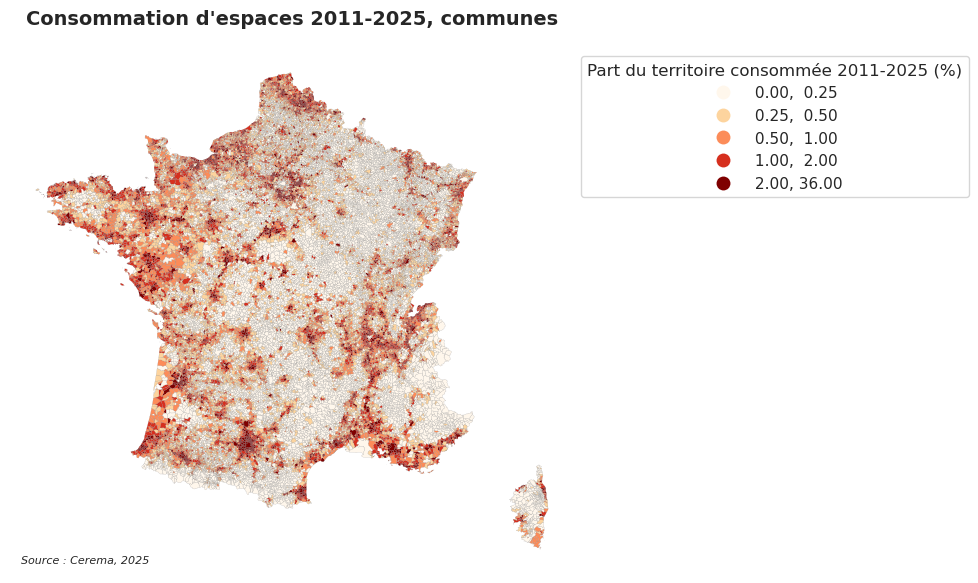

In [4]:
# Bornes communes à toutes les mailles (limite supérieure incluse) :
# classes de 0 à 0,25 %, de 0,25 à 0,5 %, de 0,5 à 1 %, de 1 à 2 % et de 2 à 36 %
BORNES = [0.25, 0.5, 1, 2, 36]
# Contrôle : aucune valeur ne doit dépasser la dernière borne
assert all(g['txartif'].max() <= BORNES[-1] for g in mailles.values()), "une valeur dépasse la dernière borne"


def carte(gdf, nom, epaisseur=0.1):
    """Carte choroplèthe d'une maille, avec les bornes communes."""
    # ÉTAPE 1 : une figure, mêmes dimensions pour toutes les mailles
    fig, ax = plt.subplots(1, 1, figsize=(9, 6))
    # ÉTAPE 2 : la carte, avec des classes définies par l'utilisateur
    gdf.plot(column='txartif', cmap='OrRd', scheme='user_defined', classification_kwds={'bins': BORNES, 'lowest': 0},
             legend=True, ax=ax, edgecolor='grey', linewidth=epaisseur,
             legend_kwds={'title': LEG, 'loc': 'upper left', 'bbox_to_anchor': (1, 1), 'frameon': True, 'fmt': '{:.2f}'})
    # ÉTAPE 3 : titre, source, sans axes
    ax.set_title(f"Consommation d'espaces 2011-2025, {nom}", fontsize=14, fontweight='bold')
    ax.axis('off')
    ax.text(0.02, 0.02, 'Source : Cerema, 2025', transform=ax.transAxes, fontsize=8, style='italic')
    plt.tight_layout()
    plt.show()


# Exemple : la carte des communes
carte(com_artif, "communes")

## 2.2 - Les autres mailles

**À vous.** Appelez `carte()` pour chaque maille, comme dans l'exemple des EPCI. Plus les unités sont grandes, plus on peut épaissir les contours.

> `📝` Cartographiez les EPCI, les départements, les anciennes et les nouvelles régions avec les mêmes bornes

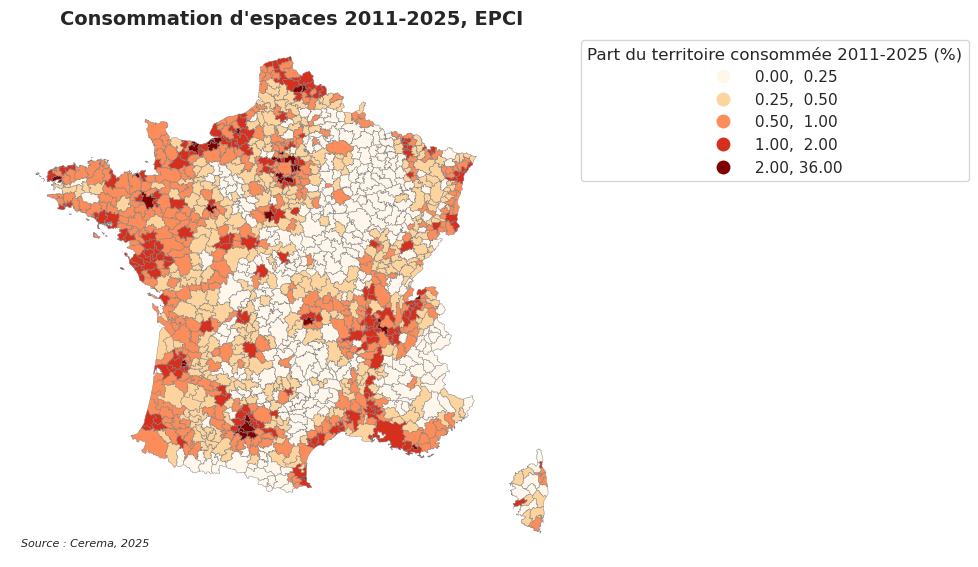

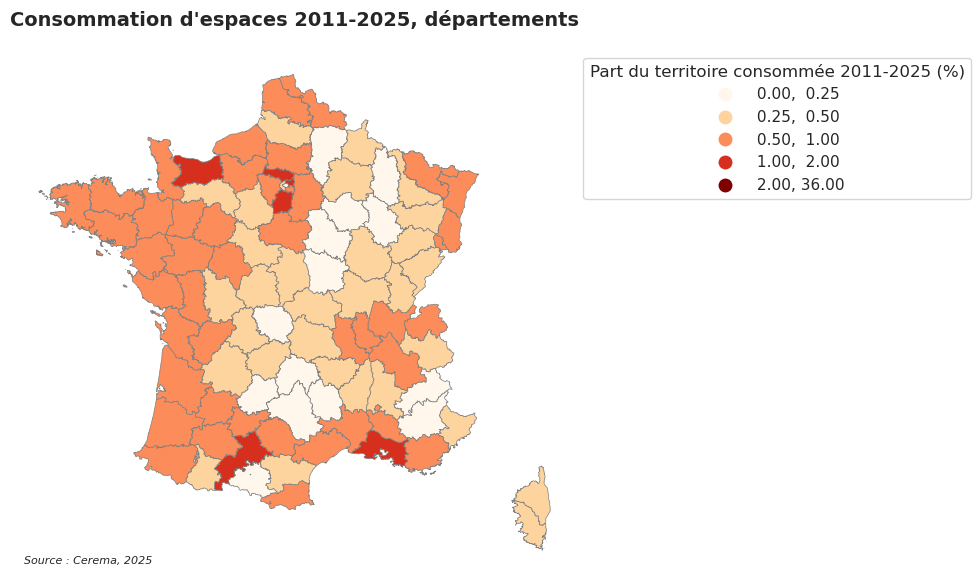

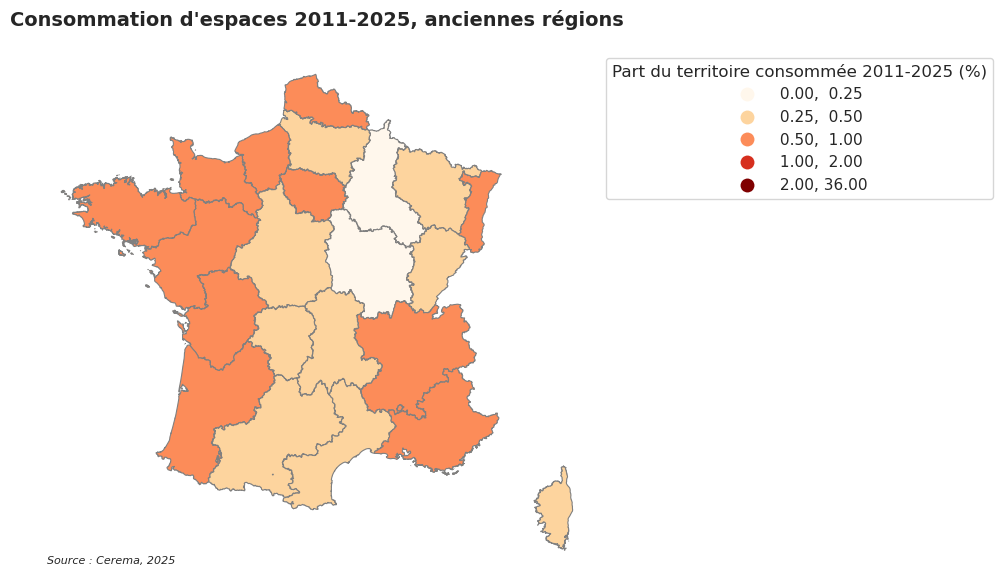

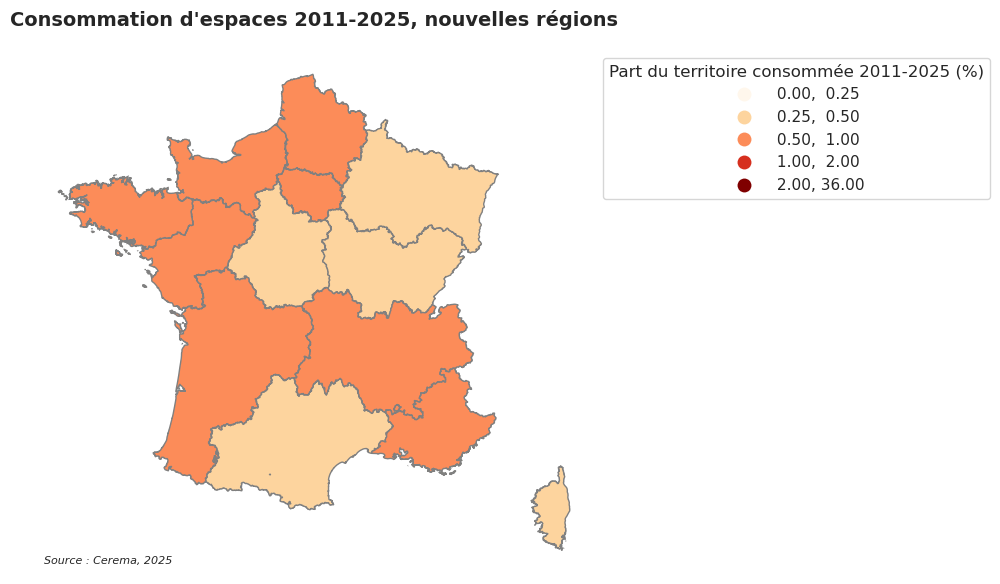

,Communes,EPCI,Départements,Anciennes régions,Nouvelles régions
txartif,,,,,
"(-0.001, 0.25]",15315,313,15,2,0
"(0.25, 0.5]",7128,339,31,9,5
"(0.5, 1.0]",6167,357,44,11,8
"(1.0, 2.0]",3975,189,6,0,0
"(2.0, 36.0]",2150,37,0,0,0


In [5]:
carte(epci_artif, "EPCI", epaisseur=0.3)
carte(dep_artif, "départements", epaisseur=0.5)
carte(oldreg_artif, "anciennes régions", epaisseur=0.8)
carte(reg_artif, "nouvelles régions", epaisseur=1)

# Effectifs par classe, pour chiffrer les observations
effectifs = pd.DataFrame({nom: pd.cut(g['txartif'], [0] + BORNES, include_lowest=True).value_counts(sort=False)
                          for nom, g in mailles.items()})
effectifs

## 2.3 - Questions

> `📝` **Question 1 :** Comment la carte change-t-elle de la commune à la région ?
>
> `📝` **Question 2 :** Les zones qui ont le plus consommé restent-elles les mêmes à chaque maille ?
>
> `📝` **Question 3 :** Quelle maille vous semble la plus pertinente pour étudier la consommation d'espaces ? Pourquoi ?

**Réponses :**


1. Avec les mêmes bornes, 15 315 communes ont consommé moins de 0,25 % de leur surface en 14 ans et 2 150 plus de 2 %. Aux EPCI, 37 dépassent encore 2 %. Aux départements, plus aucun ; le maximum tombe à 1,4 % (Seine-Saint-Denis). Les 13 régions tiennent dans deux classes, entre 0,25 et 1 %. En agrégeant, les fortes valeurs communales (couronnes des grandes villes, littoral atlantique, Alsace, vallée du Rhône) se diluent dans des unités plus grandes et les classes extrêmes disparaissent. Ce constat dépend en partie des bornes choisies. Avec d'autres seuils, l'impression de contraste changerait, mais pas la disparition des extrêmes.

2. En partie seulement. L'Île-de-France, la Bretagne et les Pays de la Loire restent parmi les plus consommatrices à toutes les mailles. Toulouse, Bordeaux ou Montpellier ressortent nettement aux EPCI, puis se fondent dans des régions proches de la moyenne. L'Alsace (0,64 %) dépasse la moyenne en ancienne région, mais le Grand Est n'atteint que 0,34 %. Un pôle de consommation reste visible tant que la maille est plus petite que lui. Les limites des unités comptent aussi, pas seulement leur taille.

3. Il n'existe pas de maille pertinente dans l'absolu. Pour un document d'urbanisme, la commune ou l'EPCI (qui porte souvent le plan local d'urbanisme intercommunal) correspond à l'échelle de décision. Pour suivre l'objectif national de réduction de la consommation d'espaces, la région est la maille des schémas régionaux (SRADDET). Le choix dépend de la question posée, ce qui est le cœur du MAUP.

---

# 3 - Analyse univariée

Décrivez la distribution du taux à chaque maille, avec ses valeurs centrales et sa dispersion.

## 3.1 - Tableau comparatif

**Exemple à exécuter.** La fonction `resume()` calcule les statistiques du taux pour une maille : moyenne, médiane (valeur qui coupe les unités en deux moitiés), écart-type (dispersion autour de la moyenne), minimum et maximum.

**À vous.** Appliquez-la à chaque maille et rassemblez les résultats dans un tableau.

> `📝` Calculez pour chaque maille la moyenne, la médiane, l'écart-type, le minimum et le maximum du taux, puis rassemblez-les dans un tableau

In [6]:
def resume(nom, gdf):
    """Statistiques descriptives du taux pour une maille."""
    t = gdf['txartif']  # la colonne du taux
    return {'Maille': nom, 'Unités': len(gdf), 'Moyenne': t.mean(), 'Médiane': t.median(),
            'Écart-type': t.std(), 'Minimum': t.min(), 'Maximum': t.max()}


# Exemple : les statistiques des communes
resume('Communes', com_artif)

{'Maille': 'Communes',
 'Unités': 34735,
 'Moyenne': np.float64(0.6166819260642504),
 'Médiane': np.float64(0.304433748902698),
 'Écart-type': np.float64(0.9672824994259818),
 'Minimum': np.float64(0.0),
 'Maximum': np.float64(35.65111044151792)}

In [7]:
tableau = pd.DataFrame([resume(nom, gdf) for nom, gdf in mailles.items()])
tableau.round(2)

,Maille,Unités,Moyenne,Médiane,Écart-type,Minimum,Maximum
0,Communes,34735,0.62,0.30,0.97,0.00,35.65
1,EPCI,1235,0.64,0.46,0.61,0.03,8.61
2,Départements,96,0.55,0.53,0.29,0.00,1.42
3,Anciennes régions,22,0.55,0.52,0.22,0.24,0.95
4,Nouvelles régions,13,0.57,0.53,0.20,0.29,0.94


## 3.2 - Boxplots côte à côte

Rien à écrire ici : exécutez la cellule et lisez le graphique.

Comment lire un boxplot : la boîte contient la moitié centrale des unités, le trait au milieu est la médiane, les moustaches s'étendent vers les valeurs plus rares et les points au-delà sont des valeurs extrêmes. Plus la boîte est haute, plus les unités se ressemblent peu.

Le graphique coupe l'axe à 5 % pour que les boîtes restent lisibles. Le nombre d'unités au-delà est écrit au-dessus de chaque boîte.

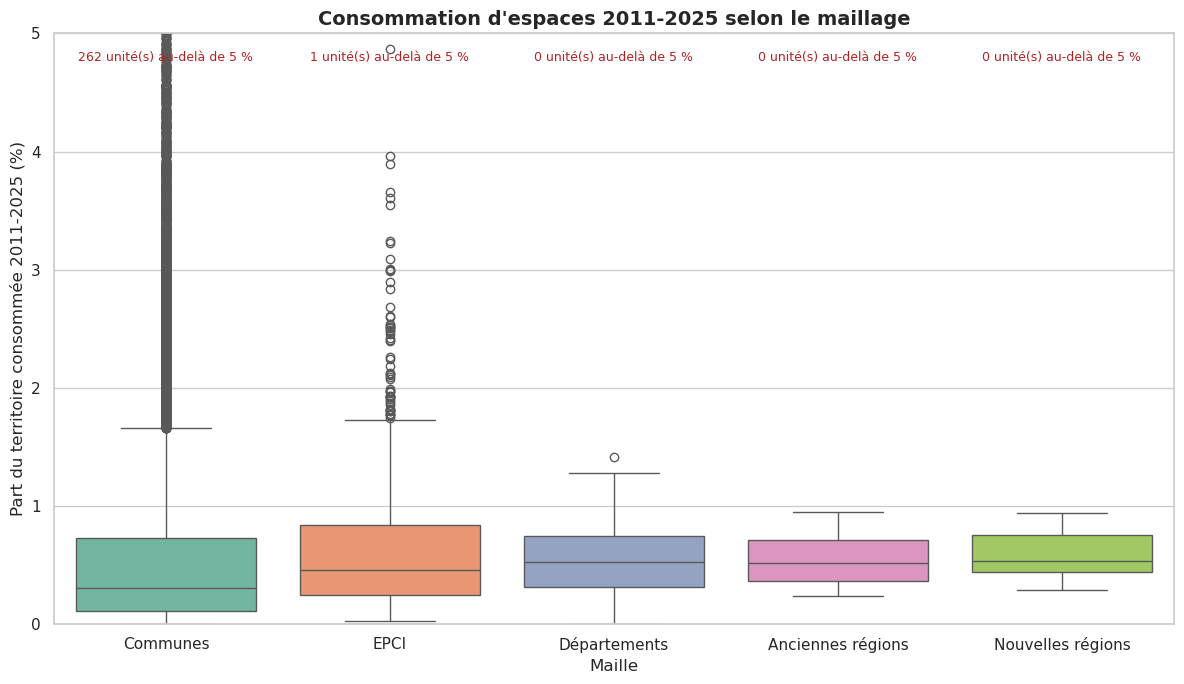

In [8]:
# Un DataFrame au format « long » pour seaborn : une ligne par unité, sa maille et son taux
df_long = pd.concat({nom: gdf['txartif'] for nom, gdf in mailles.items()}, names=['Maille', 'index']).reset_index(name=LEG)

PLAFOND = 5
fig, ax = plt.subplots(1, 1, figsize=(12, 7))
sns.boxplot(data=df_long, x='Maille', y=LEG, ax=ax, hue='Maille', palette='Set2', legend=False)
ax.set_ylim(0, PLAFOND)
for i, (nom, gdf) in enumerate(mailles.items()):
    n = int((gdf['txartif'] > PLAFOND).sum())
    ax.text(i, PLAFOND * 0.97, f"{n} unité(s) au-delà de {PLAFOND} %", ha='center', va='top', fontsize=9, color='firebrick')
ax.set_title("Consommation d'espaces 2011-2025 selon le maillage", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3.3 - Questions

> `📝` **Question 1 :** Comment évoluent la moyenne et la médiane selon la maille ?
>
> `📝` **Question 2 :** Comment évolue la dispersion selon la maille ? Pourquoi ?
>
> `📝` **Question 3 :** Quel lien faites-vous entre ces observations et le MAUP ?

**Réponses :**


| Maille | Unités | Moyenne | Médiane | Écart-type |
|:--|--:|--:|--:|--:|
| Communes | 34 735 | 0,62 | 0,30 | 0,97 |
| EPCI | 1 235 | 0,64 | 0,46 | 0,61 |
| Départements | 96 | 0,55 | 0,53 | 0,29 |
| Anciennes régions | 22 | 0,55 | 0,52 | 0,22 |
| Régions | 13 | 0,57 | 0,53 | 0,20 |

1. La moyenne varie peu, de 0,55 à 0,64 %. La médiane bouge davantage, de 0,30 % à la commune à 0,53 % aux régions. À la commune, la moitié des communes a consommé moins de 0,30 % de sa surface, mais quelques communes très consommatrices tirent la moyenne vers le haut. En agrégeant, chaque unité se rapproche du taux de la France métropolitaine (0,53 %).

2. L'écart-type passe de 0,97 point à la commune à 0,20 aux régions. Sur les boxplots, 262 communes dépassent 5 %, une seule EPCI, aucun département. Une grande maille regroupe des communes très consommatrices et d'autres qui n'ont presque rien consommé ; les extrêmes se compensent à l'intérieur de chaque unité. Ce resserrement vaut pour ces découpages. Ce n'est pas une règle générale (un découpage qui regrouperait les communes les plus consommatrices garderait une forte dispersion).

3. Il s'agit de l'effet d'échelle. Les données et la question sont les mêmes, seule la taille des unités change. Pourtant le diagnostic change. À la commune, la consommation d'espaces apparaît très concentrée ; aux régions, presque uniforme. Aucune des deux lectures n'est fausse. Chacune décrit la variabilité qui reste visible à sa maille.

---

# 4 - Analyse bivariée

La consommation d'espaces suit-elle la croissance de la population ? Les fichiers contiennent la population de 2011 et de 2022 (`pop11`, `pop22`). Vous allez mesurer leur corrélation R à chaque maille.

Les périodes diffèrent. La croissance porte sur 2011-2022, la consommation sur 2011-2025.

> `📝` Calculez la croissance de la population entre 2011 et 2022 (en %) pour chaque maille
>
> `📝` Calculez le coefficient de corrélation R entre cette croissance et le taux de consommation d'espaces

## 4.1 - Communes

**Exemple à exécuter.** La fonction `nuage()` fait trois choses pour une maille : elle calcule la croissance de la population entre 2011 et 2022, puis le coefficient de corrélation R avec le taux de consommation d'espaces, puis trace le nuage de points (une unité = un point). R varie de -1 à 1 : proche de 0, les deux variables ne varient pas ensemble de façon linéaire. Il est calculé sur toutes les unités, même si le cadre du graphique en coupe quelques-unes (leur nombre est indiqué sur la figure).

Communes : R = 0.28 (34729 unités)


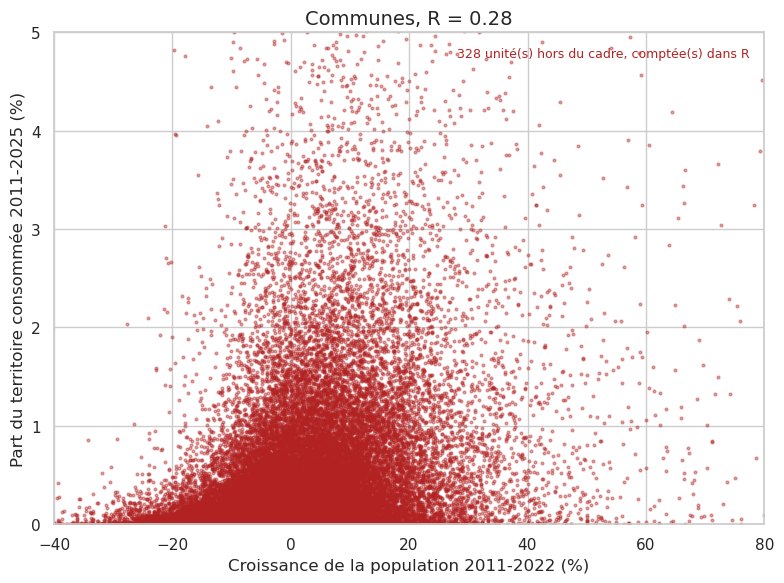

In [9]:
def nuage(gdf, nom):
    """Calcule R entre croissance de la population et taux de consommation, puis trace le nuage de points."""
    # Quelques unités n'avaient aucun habitant en 2011 : leur croissance n'est pas définie, on les écarte
    d = gdf[gdf['pop11'] > 0].copy()
    # Croissance de la population entre 2011 et 2022, en %
    d['croissance'] = 100 * (d['pop22'] - d['pop11']) / d['pop11']

    # Coefficient de corrélation R entre le taux de consommation et la croissance
    r = d['txartif'].corr(d['croissance'])
    print(f"{nom} : R = {r:.2f} ({len(d)} unités)")

    # Cadre du graphique : les points hors cadre ne sont pas dessinés, mais restent comptés dans R
    XLIM, YLIM = (-40, 80), (0, 5)
    hors = ~(d['croissance'].between(*XLIM) & d['txartif'].between(*YLIM))

    fig, ax = plt.subplots(1, 1, figsize=(8, 6))
    # Points plus gros quand il y a peu d'unités
    ax.scatter(d['croissance'], d['txartif'], s=4 if len(d) > 1000 else 40, alpha=0.4, color='firebrick')
    ax.set_title(f"{nom}, R = {r:.2f}", fontsize=14)
    ax.set_xlabel('Croissance de la population 2011-2022 (%)')
    ax.set_ylabel(LEG)
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.text(0.98, 0.97, f"{hors.sum()} unité(s) hors du cadre, comptée(s) dans R", transform=ax.transAxes,
            ha='right', va='top', fontsize=9, color='firebrick')
    plt.tight_layout()
    plt.show()


# Exemple : les communes
nuage(com_artif, "Communes")

## 4.2 - Les autres mailles

**À vous.** Appelez `nuage()` pour chaque maille. Le titre du graphique et le texte affiché sous la cellule donnent la valeur de R : notez-la pour chaque maille.

> `📝` Calculez R pour les EPCI, les départements, les anciennes et les nouvelles régions
>
> `📝` Comparez les nuages de points d'une maille à l'autre

Communes : R = 0.28 (34729 unités)


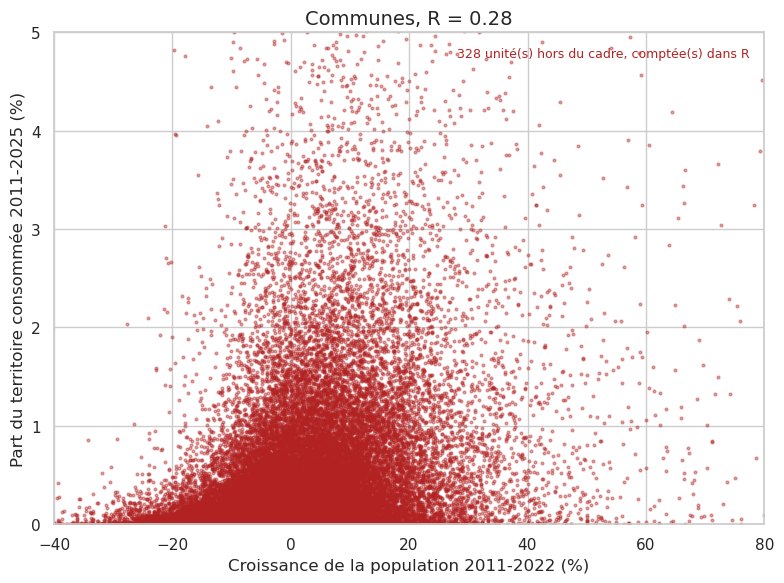

EPCI : R = 0.52 (1235 unités)


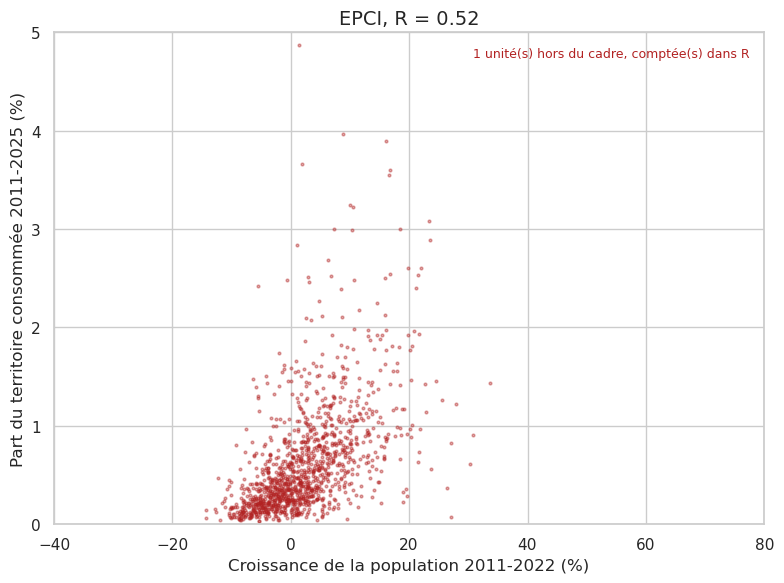

Départements : R = 0.60 (96 unités)


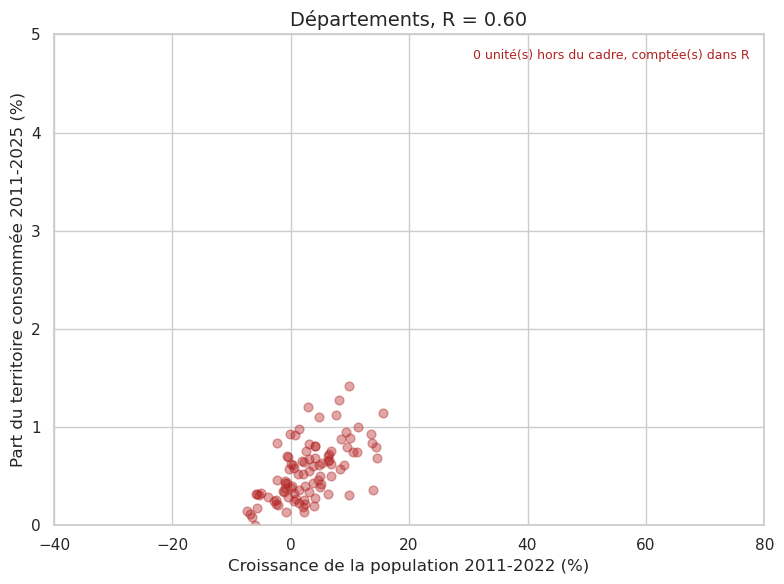

Anciennes régions : R = 0.26 (22 unités)


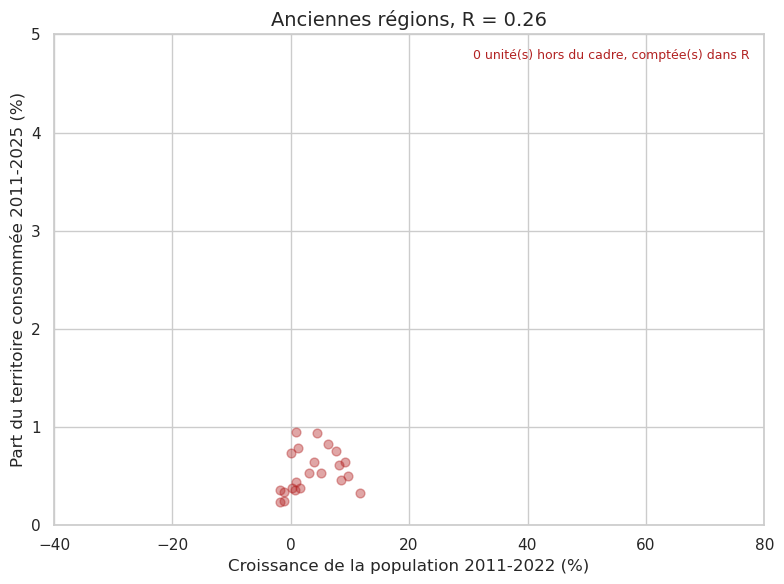

Nouvelles régions : R = 0.08 (13 unités)


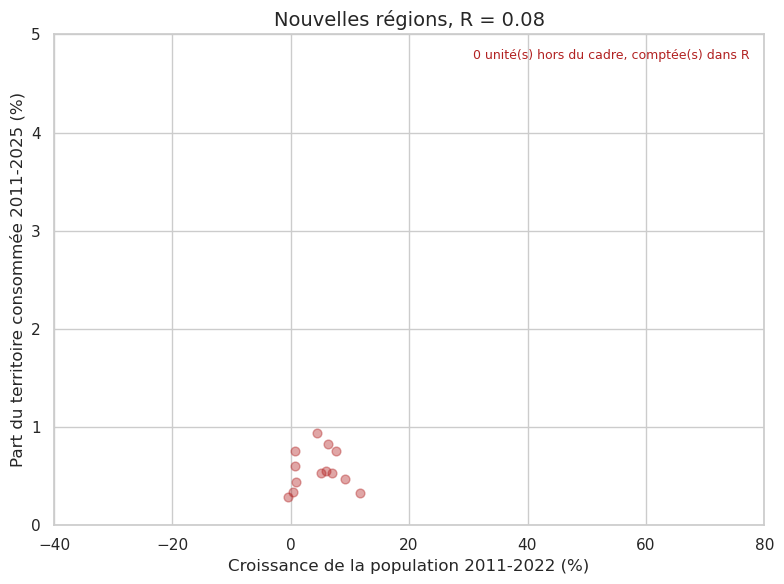

In [10]:
for nom, gdf in mailles.items():
    nuage(gdf, nom)

## 4.3 - Questions

> `📝` **Question 1 :** Comment évolue R de la commune à la région ?
>
> `📝` **Question 2 :** Que pèse un point quand il ne reste que 13 régions ? Un R proche de zéro montre-t-il l'absence de relation ?
>
> `📝` **Question 3 :** Ce calcul permet-il de dire que la croissance démographique cause la consommation d'espaces ?

**Réponses :**


1. R vaut 0,28 aux communes, 0,52 aux EPCI, 0,60 aux départements, 0,26 aux anciennes régions et 0,08 aux régions. La relation n'est pas monotone. Selon la maille, on conclurait à une association faible, nette ou presque nulle. À la commune, une seule opération (un lotissement, une zone d'activité) suffit sans doute à faire varier le taux d'une petite commune, ce qui disperse le nuage. Les graphiques seuls ne permettent pas de le vérifier.

2. Avec 13 points, un ou deux points atypiques suffisent à faire varier R. La Corse a la plus forte croissance (+11,7 %) avec l'un des taux les plus faibles (0,33 %). À l'inverse, la Normandie et les Hauts-de-France consomment beaucoup avec une population presque stable. Un R proche de zéro indique une faible association **linéaire** dans ces 13 régions. Il ne démontre pas l'absence de relation.

3. Non. R mesure une association entre unités, pas une cause. La consommation peut précéder l'arrivée d'habitants (on construit, puis on s'installe), la suivre, ou dépendre d'un troisième facteur comme l'emploi. Les périodes diffèrent aussi (2011-2022 pour la population, 2011-2025 pour la consommation).

---

# Synthèse

Le même total (290 666 hectares consommés entre 2011 et 2025) produit cinq images différentes de la consommation d'espaces.

Avec des bornes identiques, les classes extrêmes disparaissent de la commune à la région et l'écart-type est divisé par cinq. Les pôles de consommation (Val d'Europe, couronnes de Toulouse ou de Bordeaux) s'effacent au profit d'un contraste entre l'Ouest et le Nord-Est. C'est l'effet d'échelle.

Le passage des 22 anciennes aux 13 nouvelles régions change à la fois les limites, le nombre et la taille des unités. Le Nord-Pas-de-Calais, ancienne région la plus consommatrice (0,95 %), devient avec la Picardie les Hauts-de-France, cinquièmes sur treize avec 0,60 %. Ce cas réel mêle donc effet de zonage et effet d'échelle. Pour isoler le zonage, il faudrait comparer des découpages de même nombre d'unités, comme les grilles décalées du cours.

La corrélation entre consommation d'espaces et croissance de la population vaut 0,28 aux communes, 0,60 aux départements et 0,08 aux régions. Elle décrit une association entre unités, pas une cause.

Deux précautions en découlent. Un taux se recalcule à partir des surfaces sommées, jamais en faisant la moyenne des taux. Pour comparer des mailles, les bornes restent les mêmes d'une carte à l'autre. Il faudrait enfin indiquer la maille de chaque carte, puis vérifier si la conclusion tient à une autre maille.

---

# Tâche individuelle

Chacun rédige seul une courte réponse (une demi-page) sur un indicateur qui n'a pas été vu en TD, par exemple la part des logements vacants par commune. Quelle représentation choisir ? Quelles classes proposer ? Que pourrait modifier un passage à une autre maille (EPCI, département), dans la carte comme dans les conclusions ?

---

# 5 - Pour aller plus loin : corrections

Les trois pistes de la fin du sujet sont traitées ci-dessous. Elles réutilisent les cinq GeoDataFrames de la partie 1.

## 5.1 - Autocorrélation spatiale

> `📝` Calculez l'indice de Moran du taux de consommation d'espaces à chaque maille avec `esda`

In [11]:
# pip install esda libpysal si besoin
from libpysal.weights import Queen
from esda.moran import Moran

np.random.seed(0)  # permutations reproductibles
moran = []
for nom, gdf in mailles.items():
    w = Queen.from_dataframe(gdf, use_index=False, silence_warnings=True)
    w.transform = 'r'
    mi = Moran(gdf['txartif'], w, permutations=99)
    moran.append({'Maille': nom, 'Unités': len(gdf), 'I de Moran': round(mi.I, 2), 'p (permutations)': mi.p_sim})
print(pd.DataFrame(moran))

              Maille  Unités  I de Moran  p (permutations)
0           Communes   34735        0.42              0.01
1               EPCI    1235        0.44              0.01
2       Départements      96        0.23              0.01
3  Anciennes régions      22        0.07              0.22
4  Nouvelles régions      13        0.12              0.16


**Lecture :** l'indice de Moran est proche de 0,4 aux communes et aux EPCI (p = 0,01, la plus petite valeur possible avec 99 permutations). Les communes consommatrices sont voisines d'autres communes consommatrices. Aux départements, l'indice tombe à 0,23. Aux anciennes et nouvelles régions, il n'est plus significatif (p supérieur à 0,1).

Cela ne veut pas dire que la structure spatiale disparaît. Avec 13 unités, le test n'a presque aucune puissance. La plus grande part de l'autocorrélation se trouve à l'intérieur des régions, entre communes voisines. L'autocorrélation mesurée dépend elle aussi de la maille.

## 5.2 - Le changement de découpage de 2016

> `📝` Rattachez chaque ancienne région à sa région actuelle, puis comparez leurs rangs

In [12]:
# Région actuelle de chaque ancienne région, lue sur les communes
passage = com_artif[['insee_old_reg', 'insee_reg']].drop_duplicates()

zonage = (oldreg_artif[['insee_old_reg', 'txartif']]
          .merge(passage, on='insee_old_reg')
          .merge(reg_artif[['insee_reg', 'txartif']], on='insee_reg', suffixes=('_ancienne', '_nouvelle')))
zonage['rang_ancienne'] = zonage['txartif_ancienne'].rank(ascending=False).astype(int)
print(zonage.sort_values(['insee_reg', 'txartif_ancienne'], ascending=[True, False]).round(2).to_string(index=False))

insee_old_reg  txartif_ancienne insee_reg  txartif_nouvelle  rang_ancienne
           11              0.94        11              0.94              2
           24              0.44        24              0.44             14
           43              0.36        27              0.29             17
           26              0.25        27              0.29             21
           23              0.78        28              0.75              4
           25              0.73        28              0.75              6
           31              0.95        32              0.60              1
           22              0.38        32              0.60             16
           42              0.64        44              0.34              8
           41              0.34        44              0.34             19
           21              0.24        44              0.34             22
           52              0.76        52              0.76              5
           53            

**Lecture :** trois fusions changent nettement la carte. Le Nord-Pas-de-Calais, première des anciennes régions (0,95 %), est fusionné avec la Picardie (0,38 %) ; les Hauts-de-France tombent à 0,60 %, au cinquième rang sur treize. L'Alsace (0,64 %, huitième) disparaît dans le Grand Est (0,34 %), aux côtés de la Lorraine et de la Champagne-Ardenne, la moins consommatrice des 22 anciennes régions. À l'inverse, le Limousin (0,36 %) remonte à 0,55 % dans la Nouvelle-Aquitaine, entraîné par l'Aquitaine.

Le phénomène observé et la France entière sont les mêmes. Mais les limites, le nombre (22 puis 13) et la taille des unités changent ensemble. Cette comparaison montre l'effet d'un redécoupage réel, sans séparer l'effet de zonage de l'effet d'échelle. Une politique qui ciblerait les régions « les plus consommatrices » ne viserait pas les mêmes territoires avant et après 2016.

## 5.3 - Lissage spatial

> `📝` En chaque point d'une grille de 5 km, sommez les surfaces des communes dont le centroïde est à moins de 20 km, puis calculez le taux

count    21964.000000
mean         0.528480
std          0.390743
min          0.008278
25%          0.236409
50%          0.430364
75%          0.717938
max          3.016800
Name: txartif, dtype: float64


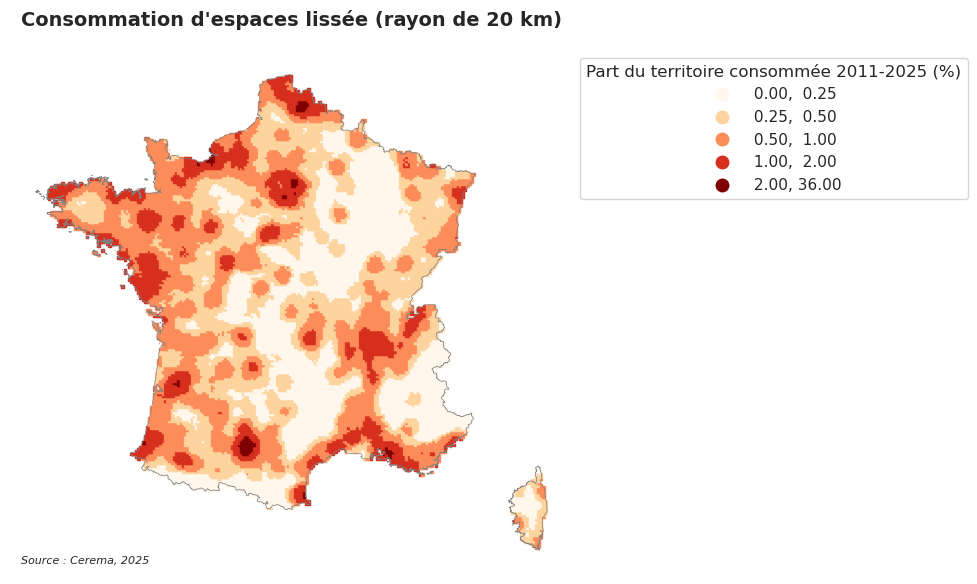

In [13]:
from scipy.spatial import cKDTree

PAS, RAYON = 5000, 20000  # m

# Centroïdes des communes (Lambert-93)
xy = np.column_stack([com_artif.centroid.x, com_artif.centroid.y])
arbre = cKDTree(xy)

# Grille de points couvrant la France métropolitaine
xmin, ymin, xmax, ymax = com_artif.total_bounds
gx, gy = np.meshgrid(np.arange(xmin, xmax, PAS), np.arange(ymin, ymax, PAS))
grille = np.column_stack([gx.ravel(), gy.ravel()])

# Pour chaque point : somme des surfaces des communes voisines, puis rapport des sommes
voisins = arbre.query_ball_point(grille, RAYON)
artif = com_artif['surface_artif'].to_numpy()
surface = com_artif['surface_com'].to_numpy()
num = np.array([artif[v].sum() for v in voisins])
den = np.array([surface[v].sum() for v in voisins])
taux = np.where(den > 0, 100 * num / np.where(den > 0, den, 1), np.nan)

# On ne garde que les points situés en France
lisse = gpd.GeoDataFrame({'txartif': taux}, geometry=gpd.points_from_xy(grille[:, 0], grille[:, 1]),
                         crs=com_artif.crs)
contour = reg_artif.dissolve()
lisse = lisse[lisse.within(contour.geometry.iloc[0])]
print(lisse['txartif'].describe())

fig, ax = plt.subplots(1, 1, figsize=(9, 6))
lisse.plot(column='txartif', cmap='OrRd', scheme='user_defined', classification_kwds={'bins': BORNES, 'lowest': 0},
           legend=True, ax=ax, markersize=4, marker='s',
           legend_kwds={'title': LEG, 'loc': 'upper left', 'bbox_to_anchor': (1, 1), 'frameon': True, 'fmt': '{:.2f}'})
contour.boundary.plot(ax=ax, color='grey', linewidth=0.5)
ax.set_title("Consommation d'espaces lissée (rayon de 20 km)", fontsize=14, fontweight='bold')
ax.axis('off')
ax.text(0.02, 0.02, 'Source : Cerema, 2025', transform=ax.transAxes, fontsize=8, style='italic')
plt.tight_layout()
plt.show()

**Lecture :** le lissage atténue les frontières visibles des unités administratives. Il reste dépendant des données communales, des centroïdes et du rayon choisi. Chaque point de la grille porte le rapport des surfaces sommées dans un disque de 20 km. Les pôles visibles aux EPCI réapparaissent (Île-de-France, Toulouse, Bordeaux, Nantes et le littoral vendéen, Rennes, Lyon, le littoral méditerranéen, l'Alsace).

La moyenne des points lissés est proche du taux national, sans que rien ne le garantisse. Les disques se chevauchent et ceux du bord couvrent moins de surface. Le lissage ne supprime pas le MAUP pour autant. Le choix du rayon remplace celui de la maille. Avec 5 km, la carte se rapprocherait de celle des communes ; avec 50 km, de celle des départements.